# Early Warning of Food-Price Spikes in Tanzanian Markets
**Z3003 Data Mining: Scaling to Large Data — Mini-Project** · Shambhavi Srivastava (ZDA24B005) · BS Semester 5 (DSAI), IIT Madras Zanzibar

| | |
|---|---|
| **Decision question** | One month ahead, which market–commodity price series will see a **price spike** (a rise of more than 10% on the previous month), so that the **Ministry of Agriculture** can act early — releasing reserve stock or prioritising market monitoring? |
| **Mining task** | Classification (Weeks 6–7): predict `price_spike` (Yes/No) for month *t+1* using only information available at the end of month *t*. |
| **Dataset** | WFP *United Republic of Tanzania — Food Prices* and companion *Markets* table, via the Humanitarian Data Exchange (HDX). Licence CC BY-IGO. |
| **Approval** | Approved by Dr. I. Nyalala on 20 Oct 2026, with three conditions: **(1)** build every feature only from months before the month being predicted; **(2)** justify the 10% spike threshold; **(3)** convert prices to a common unit before modelling. Where each condition is met is flagged with **[Condition 1/2/3]**. |

**Data citation.** World Food Programme (2026). *United Republic of Tanzania — Food Prices* [`wfp_food_prices_tza.csv`, submitted as `Shambhavi_MiniProject_Data.csv`] and *Markets* [`wfp_markets_tza.csv`, submitted as `Shambhavi_MiniProject_Markets.csv`]. Humanitarian Data Exchange. https://data.humdata.org/dataset/wfp-food-prices-for-united-republic-of-tanzania. Licensed under CC BY-IGO. Downloaded 9 November 2026 (latest month in the file: September 2026).

**Note on the data version.** WFP updates this file monthly. The approval email (20 Oct) described an earlier version (65,107 rows, to Aug 2026); the version analysed here has 67,999 rows to Sep 2026. The structure is unchanged.

**Structure.** 1 Data understanding · 2 Exploratory analysis · 3 Preprocessing · 4 Mining · 5 Findings & discussion · References · Tools used.

In [1]:
# ---- Setup -------------------------------------------------------------------
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

def find_file(*names):
    # Look for each accepted name in data/, the notebook's own folder, then any Kaggle input folder.
    for name in names:
        candidates = [Path("data") / name, Path(name)] + sorted(Path("/kaggle/input").glob(f"**/{name}"))
        for p in candidates:
            if p.exists():
                return p
    raise FileNotFoundError(f"None of {names} found. Put the file in a 'data/' folder next to this notebook.")

# Submission names first (brief §2); the original WFP download names are accepted as a fallback.
PRICES_PATH  = find_file("Shambhavi_MiniProject_Data.csv", "wfp_food_prices_tza.csv")     # main price table
MARKETS_PATH = find_file("Shambhavi_MiniProject_Markets.csv", "wfp_markets_tza.csv")      # companion markets table
print("Using:", PRICES_PATH, "|", MARKETS_PATH)
RANDOM_STATE = 42                                      # one seed for every random step

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Plot style: recessive grid, thin marks, one fixed colour per entity
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
COLOR = {"Retail": "#2a78d6", "Wholesale": "#eb6834"}   # fixed: Retail = blue, Wholesale = orange

# Library versions, for reproducibility and for the References section
import sys, matplotlib, scipy
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | scipy {scipy.__version__}")

Using: wfp_food_prices_tza.csv | wfp_markets_tza.csv
Python 3.12.6 | pandas 3.0.2 | numpy 2.4.1 | matplotlib 3.10.8 | scipy 1.17.1


---
# 1 · Data Understanding

## 1.1 Shape of the data and what one row represents

In [2]:
df = pd.read_csv(PRICES_PATH, parse_dates=["date"])
markets = pd.read_csv(MARKETS_PATH)

print(f"Price table  : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Markets table: {markets.shape[0]:,} rows × {markets.shape[1]} columns")
print(f"Date range   : {df['date'].min():%b %Y} – {df['date'].max():%b %Y}")
df.head()

Price table  : 65,107 rows × 16 columns
Markets table: 123 rows × 7 columns
Date range   : Jan 2006 – Aug 2026


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Arusha,Arusha Urban,Arusha (urban),80,-3.37,36.68,cereals and tubers,Maize,51,100 KG,actual,Wholesale,TZS,38464.29,32.46
1,2006-01-15,Arusha,Arusha Urban,Arusha (urban),80,-3.37,36.68,pulses and nuts,Beans,50,100 KG,actual,Wholesale,TZS,80714.29,68.11
2,2006-01-15,Dar-es-salaam,Ilala,Dar Es Salaam,83,-6.80,39.28,cereals and tubers,Maize,51,100 KG,actual,Wholesale,TZS,38742.86,32.69
3,2006-01-15,Dar-es-salaam,Ilala,Dar Es Salaam,83,-6.80,39.28,cereals and tubers,Rice,52,100 KG,actual,Wholesale,TZS,64545.45,54.47
4,2006-01-15,Dar-es-salaam,Ilala,Dar Es Salaam,83,-6.80,39.28,pulses and nuts,Beans,50,100 KG,actual,Wholesale,TZS,80000.00,67.51


In [3]:
# What is ONE row? Test the candidate key: market × commodity × unit × price type × month.
SERIES_KEY = ["market_id", "commodity", "unit", "pricetype"]

n_dup_rows = df.duplicated().sum()
n_dup_key  = df.duplicated(SERIES_KEY + ["date"]).sum()
n_series   = df.groupby(SERIES_KEY).ngroups
day_of_month = df["date"].dt.day.unique()

print(f"Fully duplicated rows                        : {n_dup_rows}")
print(f"Duplicates on (series key + month)           : {n_dup_key}")
print(f"Distinct price series (market×commodity×unit×type): {n_series}")
print(f"Day-of-month values in 'date'                : {day_of_month}")

Fully duplicated rows                        : 0
Duplicates on (series key + month)           : 0
Distinct price series (market×commodity×unit×type): 869
Day-of-month values in 'date'                : [15]


**What one row represents.** One row is **the monthly price of one commodity, in one market, in one unit, at one price level (retail or wholesale)** — e.g. *“wholesale maize in Arusha, per 100 kg, January 2006: 38,464 TZS.”*

- The combination *market × commodity × unit × price type × month* has **no duplicates**, so it is a valid key. This matters later: the spike label compares a row with the *same series* one month earlier, which is only well defined if each series has at most one price per month.
- The 67,999 rows belong to **870 separate price series**. The unit of analysis for the question is a *series-month*, not a market or a commodity on its own.
- Every date falls on the **15th**: WFP stamps each monthly price with the middle of the month. `date` therefore means “month”, not a specific day.

## 1.2 Attribute types

`df.dtypes` shows how pandas *stores* each column, which is not the same as its data-mining type (Tutorial 1 handout, §5). The profile below supplies the evidence for each classification.

In [4]:
profile = pd.DataFrame({
    "pandas dtype": df.dtypes.astype(str),
    "n unique":     df.nunique(),
    "example values": [", ".join(map(str, df[c].drop_duplicates().head(3).tolist())) for c in df.columns],
})
profile

,pandas dtype,n unique,example values
date,datetime64[us],247,"2006-01-15 00:00:00, 2006-02-15 00:00:00, 2006..."
admin1,str,25,"Arusha, Dar-es-salaam, Dodoma"
admin2,str,52,"Arusha Urban, Ilala, Mpwapwa"
market,str,63,"Arusha (urban), Dar Es Salaam, Dodoma (Majengo)"
market_id,int64,63,"80, 83, 84"
latitude,float64,59,"-3.37, -6.8, -7.29"
longitude,float64,59,"36.68, 39.28, 36.34"
category,str,7,"cereals and tubers, pulses and nuts, meat, fis..."
commodity,str,31,"Maize, Beans, Rice"
commodity_id,int64,31,"51, 50, 52"


Classification follows Lecture 2: **nominal** (=, ≠ only), **binary** (two states; symmetric or asymmetric), **ordinal** (adds <, >), **numeric** — **interval** (equal gaps, no true zero) or **ratio** (true zero, ratios meaningful); plus *discrete* vs *continuous*.

| # | Attribute | Type | Discrete / continuous | Valid centre | Reason |
|---|---|---|---|---|---|
| 1 | `date` | Numeric — **interval** | discrete (monthly) | median, mean | Differences are meaningful (Mar − Jan = 2 months) but there is no true zero, so “2026 is 1.0005× 2025” means nothing; same case as “calendar year” in Lecture 2. |
| 2 | `admin1` (region) | **Nominal** | discrete | mode | 25 region names with no order; we can only test equal / not equal. |
| 3 | `admin2` (district) | **Nominal** | discrete | mode | 52 district names nested inside regions; labels only. |
| 4 | `market` | **Nominal** | discrete | mode | 63 market names; labels only. |
| 5 | `market_id` | **Nominal** (identifier) | discrete | none | Stored as an integer, but it is a code: the mean of market IDs is meaningless (shown below). Same trap as `farm_id` in Tutorial 1. |
| 6 | `latitude` | Numeric — **interval** | continuous | median, mean | Equal gaps in degrees, but 0° (the equator) is a convention, not “no latitude”, and values can be negative, so ratios are meaningless. |
| 7 | `longitude` | Numeric — **interval** | continuous | median, mean | Same reasoning as latitude (0° = Greenwich, a convention). |
| 8 | `category` | **Nominal** | discrete | mode | 7 food groups (cereals, pulses, …) with no order. |
| 9 | `commodity` | **Nominal** | discrete | mode | 31 food items; labels only. |
| 10 | `commodity_id` | **Nominal** (identifier) | discrete | none | Integer code for `commodity`; arithmetic on it is meaningless. |
| 11 | `unit` | **Nominal** | discrete | mode | KG, 100 KG, MT, L. One could order the weight units by size, but L (litre) measures volume and cannot be placed on the same scale, so there is no single order: nominal. |
| 12 | `priceflag` | **Nominal** (constant) | discrete | mode | Only one value (`actual`) in this file, so it carries no information. |
| 13 | `pricetype` | **Binary — symmetric** | discrete | mode / proportion | Two states, Retail / Wholesale, and neither is the “rare, important” state: both price levels matter equally to the question. |
| 14 | `currency` | **Nominal** (constant) | discrete | mode | Only one value (`TZS`); carries no information. |
| 15 | `price` | Numeric — **ratio** | continuous | median, mean | 0 TZS means “free”, so 20,000 TZS is twice 10,000 TZS. **But** it is recorded in mixed units, so two rows are only comparable after conversion to TZS/kg **[Condition 3]**. |
| 16 | `usdprice` | Numeric — **ratio** | continuous | median, mean | Same as `price`, converted to US dollars by WFP; a derived, redundant column (see quality checks in 1.3). |
| — | `price_tzs_per_kg` *(derived, Section 3)* | Numeric — **ratio** | continuous | median, mean | `price` divided by kilograms per unit; the common unit required by Condition 3. |
| — | `price_spike` *(derived target)* | **Binary — asymmetric** | discrete | proportion | Yes / No. The two states are **not** equally important: a spike is the rare, costly event the Ministry wants to catch, so it is coded 1 and evaluated with recall/precision rather than accuracy (Lecture 1: “99.5% accuracy can catch zero fraud”). |

**No ordinal attribute exists in the raw data.** The brief requires numeric plus *at least one* of nominal / binary / ordinal, which is met. An ordinal attribute can be derived later by discretizing price change into ordered bands (Section 3).

In [5]:
# The identifier trap (Lecture 2): pandas will happily average an ID.
print(f"Mean of market_id    = {df['market_id'].mean():,.1f}   <- no market has this meaning")
print(f"Mean of commodity_id = {df['commodity_id'].mean():,.1f}   <- 'average commodity' does not exist")

# Constant columns: one value only, so zero information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", {c: df[c].iloc[0] for c in constant_cols})

# Balance of the binary attribute and size of each nominal attribute
print("\npricetype:", df["pricetype"].value_counts().to_dict())
print("unit     :", df["unit"].value_counts().to_dict())

Mean of market_id    = 3,429.2   <- no market has this meaning
Mean of commodity_id = 241.4   <- 'average commodity' does not exist
Constant columns: {'priceflag': 'actual', 'currency': 'TZS'}

pricetype: {'Retail': 43954, 'Wholesale': 21153}
unit     : {'KG': 40996, '100 KG': 21126, 'L': 2958, 'MT': 27}


## 1.3 Missing values and data quality

Missingness in a time-series table can take two forms, and both must be counted:

1. **Explicit**: an empty cell in a row that exists.
2. **Implicit**: a month with **no row at all** for a series that is otherwise being monitored. These do not show up in `isna()`, but they are what breaks a month-on-month spike label.

### 1.3.1 Explicit missing values, per column

In [6]:
explicit = pd.DataFrame({"missing cells": df.isna().sum(),
                         "% of rows": (df.isna().mean() * 100).round(2)})
explicit.T

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
missing cells,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
% of rows,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Every column is complete: 0 empty cells out of 67,999 × 16.** WFP publishes only months for which a price was collected, so a missing price is represented by a **missing row**, not a blank cell. The real missing-data question is therefore the implicit one below.

### 1.3.2 Implicit missing values: months with no row

For each of the 870 series, we build the complete list of months between its **first and last observation**, and mark each month as observed or missing. Months *before* a series starts or *after* it stops are not counted as missing: those reflect when WFP monitored that series, which is analysed separately.

In [7]:
# Work with monthly periods so that month arithmetic is exact
df["month"] = df["date"].dt.to_period("M")

spans = (df.groupby(SERIES_KEY)
           .agg(first=("month", "min"), last=("month", "max"), observed=("month", "size"),
                admin1=("admin1", "first"), category=("category", "first"))
           .reset_index())

# Full monthly grid inside each series' active span
grid = spans.loc[spans.index.repeat((spans["last"] - spans["first"]).apply(lambda x: x.n) + 1)].copy()
grid["month"] = grid["first"] + grid.groupby(level=0).cumcount()
grid = grid.reset_index(drop=True)

observed_keys = df[SERIES_KEY + ["month"]].assign(present=True)
grid = grid.merge(observed_keys, on=SERIES_KEY + ["month"], how="left")
grid["missing"] = grid["present"].isna()
grid = grid.drop(columns="present")

n_expected, n_missing = len(grid), int(grid["missing"].sum())
assert n_expected - n_missing == len(df), "every observed row must sit inside the grid"

print(f"Expected series-months (inside active spans): {n_expected:,}")
print(f"Observed                                    : {n_expected - n_missing:,}")
print(f"Missing (no row)                            : {n_missing:,}  ({n_missing / n_expected:.1%})")

per_series = grid.groupby(SERIES_KEY)["missing"].sum()
print(f"\nSeries with no gaps: {(per_series == 0).sum()} of {len(per_series)};"
      f"  worst series missing {per_series.max()} months")

Expected series-months (inside active spans): 72,748
Observed                                    : 65,107
Missing (no row)                            : 7,641  (10.5%)

Series with no gaps: 419 of 869;  worst series missing 125 months


### 1.3.3 Are the gaps random or systematic?

If gaps were **missing completely at random**, the missing rate would be about the same for every price type, region, year and calendar month. We compare the rates and test independence with a χ² test (missing yes/no × group).

In [8]:
def missing_rate(by):
    t = grid.groupby(by)["missing"].agg(missing="sum", expected="size")
    t["rate %"] = (100 * t["missing"] / t["expected"]).round(1)
    return t

def chi2_test(col):
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(grid[col], grid["missing"]))
    return f"χ² = {chi2:,.0f}, dof = {dof}, p = {p:.1e}"

print("By price type:"); display(missing_rate("pricetype"))
print("Independence test, pricetype × missing:", chi2_test("pricetype"))

by_region = missing_rate("admin1").sort_values("rate %")
print("\nBy region — 5 most and 5 least complete:")
display(pd.concat([by_region.head(5), by_region.tail(5)]))
print("Independence test, region × missing:", chi2_test("admin1"))

grid["cal_month"] = grid["month"].dt.month
print("\nBy calendar month (seasonality check), rate %:")
print(missing_rate("cal_month")["rate %"].to_dict())

By price type:


,missing,expected,rate %
pricetype,,,
Retail,2595,46549,5.6
Wholesale,5046,26199,19.3


Independence test, pricetype × missing: χ² = 3,339, dof = 1, p = 0.0e+00

By region — 5 most and 5 least complete:


,missing,expected,rate %
admin1,,,
Simiyu,87,2024,4.3
Dodoma,175,3110,5.6
Morogoro,172,3031,5.7
Tanga,181,3042,6.0
Kagera,198,3029,6.5
Njombe,389,2478,15.7
Lindi,449,2739,16.4
Dar-es-salaam,780,4748,16.4
Geita,414,2480,16.7


Independence test, region × missing: χ² = 1,264, dof = 24, p = 6.9e-252

By calendar month (seasonality check), rate %:
{1: 9.9, 2: 11.1, 3: 10.3, 4: 10.5, 5: 10.5, 6: 10.2, 7: 10.8, 8: 10.1, 9: 12.1, 10: 10.9, 11: 9.8, 12: 9.8}


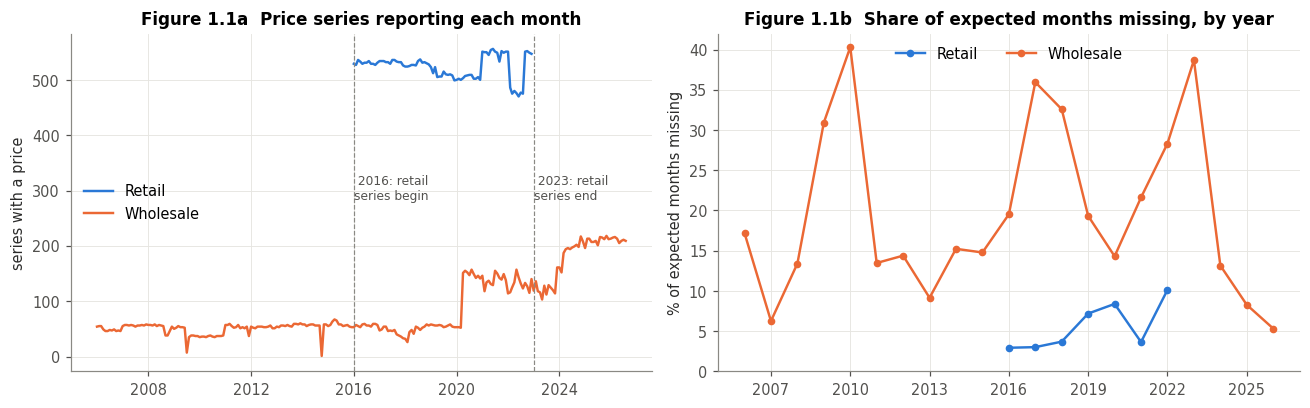

Year in which each series' LAST price appears:


last_year,2009,2014,2016,2018,2020,2021,2022,2023,2024,2026
pricetype,,,,,,,,,,
Retail,0,0,1,1,15,0,570,0,0,0
Wholesale,2,1,0,2,5,18,2,14,7,231


In [9]:
# Figure 1.1 — coverage over time: how many series report each month, by price type
cover = df.groupby(["month", "pricetype"]).size().unstack()   # NaN = price type not monitored that month
cover.index = cover.index.to_timestamp()

grid["year"] = grid["month"].dt.year
gap_year = grid.groupby(["year", "pricetype"])["missing"].mean().unstack() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for pt in ["Retail", "Wholesale"]:
    axes[0].plot(cover.index, cover[pt], color=COLOR[pt], lw=1.6, label=pt)
    axes[1].plot(gap_year.index, gap_year[pt], color=COLOR[pt], lw=1.6, marker="o", ms=4, label=pt)
for x, label in [("2016-01-01", "2016: retail\nseries begin"), ("2023-01-01", "2023: retail\nseries end")]:
    axes[0].axvline(pd.Timestamp(x), color="#8a8984", lw=0.8, ls="--")
    axes[0].text(pd.Timestamp(x), 330, " " + label, va="top", fontsize=8, color="#52514e")
axes[0].set(title="Figure 1.1a  Price series reporting each month", ylabel="series with a price")
axes[1].set(title="Figure 1.1b  Share of expected months missing, by year", ylabel="% of expected months missing")
axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].legend(loc="center left"); axes[1].legend(loc="upper center", ncol=2)
axes[1].set_ylim(0, 42)
plt.tight_layout(); plt.show()

ended = spans.assign(last_year=spans["last"].dt.year).groupby(["last_year", "pricetype"]).size().unstack(fill_value=0)
print("Year in which each series' LAST price appears:"); ended.T

**Interpretation — the gaps are systematic, not random.** In missing-data terms, they are **not missing completely at random**: the chance that a month is missing depends on observed attributes (price type, region, year).

- **Price type is the strongest driver.** Wholesale series miss **15.2%** of their months versus **2.4%** for retail; the χ² test rejects independence overwhelmingly (p ≈ 0). A likely explanation (our inference; the dataset does not document collection schedules) is that wholesale prices were collected less regularly than retail prices.
- **Region matters.** Missing rates range from about **1% (Simiyu)** to about **15% (Geita, Njombe, Mbeya)** (χ², p ≈ 0). The highest-gap markets (Geita and Njombe, added in 2015) report wholesale prices only intermittently, so a model would know least about exactly these places.
- **Time matters.** Wholesale gaps peak in **2009–2010** (about 27–36% of months), **2017–2018** (about 29–33%) and the **2022–2023 transition** (about 25–36%), the years when the retail series end and the set of wholesale markets changes (Figures 1.1a–b). Retail gaps never exceed about 8% in any year.
- **Season does not matter.** The calendar-month rate stays between 6.3% and 8.5%, so prices are not skipped in particular months of the agricultural year. This is reassuring: missing months are not hiding lean-season spikes.

**Discontinued series are a separate issue from gaps.** 572 of the 870 series (almost all retail) have their last price in 2022, consistent with retail price collection ending that year (the data do not say why); only 231 series still report in September 2026. That is a change in **coverage**, not missing data, and it decides which period the model can be tested on (Section 3/4).

*Consequence for later sections:* because gaps depend on price type and region, any imputation must be done **within each series**, using **past months only** **[Condition 1]**, never with a global mean (Section 3).

**Do the gaps hide price spikes?** A worse kind of missingness would be if prices go *unrecorded when they jump* (e.g. during a supply shock). Then gaps would be related to the very thing we want to predict. We test this by comparing the price movement across a gap, expressed per month, with ordinary month-to-month movement.

In [10]:
# Price movement across a gap vs ordinary consecutive months (KG and 100 KG series; prices in the same unit within a series)
s = df[df["unit"].isin(["KG", "100 KG"])].sort_values(SERIES_KEY + ["month"]).copy()
g = s.groupby(SERIES_KEY)
s["prev_price"] = g["price"].shift()
s["months_since_prev"] = (s["month"] - g["month"].shift()).apply(lambda x: x.n if pd.notna(x) else np.nan)
s = s.dropna(subset=["months_since_prev"])
s["after_gap"] = np.where(s["months_since_prev"] > 1, "after a gap", "consecutive months")
s["total_change"] = s["price"] / s["prev_price"] - 1
s["change_per_month"] = (s["price"] / s["prev_price"]) ** (1 / s["months_since_prev"]) - 1

gap_check = s.groupby("after_gap").agg(
    pairs=("price", "size"),
    median_abs_change_per_month=("change_per_month", lambda x: x.abs().median()),
    p75_abs_change_per_month=("change_per_month", lambda x: x.abs().quantile(0.75)),
    share_total_change_over_10pct=("total_change", lambda x: (x > 0.10).mean()),
).round(3)
gap_check

,pairs,median_abs_change_per_month,p75_abs_change_per_month,share_total_change_over_10pct
after_gap,,,,
after a gap,2352,0.027,0.066,0.258
consecutive months,58949,0.025,0.088,0.124


- **Per month, prices move about the same across a gap as between consecutive months.** The median absolute change is about **2.7% vs 2.5%** per month, and the 75th percentile is actually *lower* after a gap (**6.1% vs 8.8%**). So there is no sign that months go missing because prices jumped. The gaps look unrelated to the spikes themselves.
- **But comparing a price with the last *available* price would distort the label.** Across a gap, the total rise exceeds 10% in **28.4%** of cases, versus **12.4%** for consecutive months, simply because several months of change pile up. This is why the target in 1.4 is only defined for **consecutive** months.

### 1.3.4 Data-quality dimensions

Han, Pei & Tong (2023, Ch. 3) list six dimensions of data quality. Each is checked below against this dataset.

In [11]:
# --- ACCURACY 1: the 'MT' (metric tonne) rows -----------------------------------
# Compare each MT price with the same commodity, market type and year priced per 100 KG, scaled to per kg.
df["kg_per_unit_label"] = df["unit"].map({"KG": 1, "100 KG": 100, "MT": 1000, "L": np.nan})
df["tzs_per_kg_label"] = df["price"] / df["kg_per_unit_label"]
mt = df[df["unit"] == "MT"]
ref = (df[df["unit"] == "100 KG"].groupby(["commodity", df["date"].dt.year])["tzs_per_kg_label"].median()
         .rename("median TZS/kg from 100 KG rows"))
mt_check = (mt.assign(year=mt["date"].dt.year)
              .merge(ref, left_on=["commodity", "year"], right_index=True)
              [["date", "market", "commodity", "price", "tzs_per_kg_label", "median TZS/kg from 100 KG rows"]]
              .rename(columns={"price": "price (labelled per MT)", "tzs_per_kg_label": "implied TZS/kg if MT"}))
print(f"MT rows: {len(mt)}"); display(mt_check.head(6))
ratio = mt_check["price (labelled per MT)"] / mt_check["median TZS/kg from 100 KG rows"]
print(f"MT price ÷ same-year per-kg price from 100 KG rows: median {ratio.median():.2f}")

MT rows: 27


,date,market,commodity,price (labelled per MT),implied TZS/kg if MT,median TZS/kg from 100 KG rows
1719,2008-09-15,Dar Es Salaam,Beans,909.60,0.90960,875.00000
1757,2008-10-15,Dar Es Salaam,Beans,937.57,0.93757,875.00000
2207,2009-07-15,Dar Es Salaam,Maize,371.25,0.37125,400.00000
2208,2009-07-15,Dar Es Salaam,Rice,991.46,0.99146,1100.00000
2209,2009-07-15,Dar Es Salaam,Beans,999.13,0.99913,993.33335
2217,2009-08-15,Dar Es Salaam,Beans,1054.14,1.05414,993.33335


MT price ÷ same-year per-kg price from 100 KG rows: median 1.05


In [12]:
# --- ACCURACY 2: extreme values relative to the same commodity in the same month -------
# Price per kg relative to the national median for that commodity, price type and month.
same_unit = df[df["unit"].isin(["KG", "100 KG"])].copy()
same_unit["rel_to_national_median"] = (same_unit["tzs_per_kg_label"] /
    same_unit.groupby(["commodity", "pricetype", "date"])["tzs_per_kg_label"].transform("median"))
extreme = same_unit[(same_unit["rel_to_national_median"] > 5) | (same_unit["rel_to_national_median"] < 0.2)]
print(f"Rows more than 5× above or 5× below the national median for that commodity-month: {len(extreme)}")
extreme.sort_values("rel_to_national_median", ascending=False)[
    ["date", "market", "commodity", "unit", "price", "rel_to_national_median"]].head(8)

Rows more than 5× above or 5× below the national median for that commodity-month: 30


,date,market,commodity,unit,price,rel_to_national_median
42002,2021-01-15,Tanga Region,Beans (green),KG,3000000.0,953.076850
39216,2020-09-15,Pwani Region,Lettuce,KG,7684.9,9.372972
39860,2020-10-15,Pwani Region,Lettuce,KG,7008.4,8.352282
38562,2020-08-15,Pwani Region,Lettuce,KG,6549.8,7.866683
44563,2021-05-15,Pwani Region,Lettuce,KG,5609.4,7.370122
45945,2021-07-15,Pwani Region,Lettuce,KG,5473.2,7.247832
46650,2021-08-15,Pwani Region,Lettuce,KG,5624.2,7.143656
39219,2020-09-15,Pwani Region,Tomatoes (bitter),KG,7493.0,7.088931


In [13]:
# --- CONSISTENCY 1: does usdprice agree with price? (implied TZS per USD) ---------------
df["implied_tzs_per_usd"] = df["price"] / df["usdprice"]
yearly_rate = df.groupby(df["date"].dt.year)["implied_tzs_per_usd"].transform("median")
off = df[(df["implied_tzs_per_usd"] / yearly_rate - 1).abs() > 0.5]
print(f"Rows whose implied exchange rate is >50% away from that year's median: {len(off)}")
display(off[["date", "market", "commodity", "price", "usdprice", "implied_tzs_per_usd"]].head(5))

# --- CONSISTENCY 2: units used by each commodity ---------------------------------------
units = pd.crosstab(df["commodity"], [df["pricetype"], df["unit"]])
print("Commodities recorded in more than one unit / price type:")
display(units[(units > 0).sum(axis=1) > 1])

# --- CONSISTENCY 3: markets table vs price table ----------------------------------------
m = df.drop_duplicates("market_id")[["market_id", "market", "latitude", "longitude"]].merge(
        markets, on="market_id", how="left", suffixes=("", "_mk"))
print(f"Price-table markets missing from markets table: {m['market_mk'].isna().sum()}; "
      f"name mismatches: {(m['market'] != m['market_mk']).sum()}; "
      f"coordinate mismatches: {((m['latitude'] != m['latitude_mk']) | (m['longitude'] != m['longitude_mk'])).sum()}")

Rows whose implied exchange rate is >50% away from that year's median: 62


,date,market,commodity,price,usdprice,implied_tzs_per_usd
608,2007-01-15,Lindi,Maize,23700.00,2.0,11850.00000
681,2007-02-15,Mwanza,Maize,23700.00,2.0,11850.00000
1284,2008-01-15,Lindi,Beans,115300.00,1.0,115300.00000
1748,2008-09-15,Singida,Beans,103500.00,9.0,11500.00000
4205,2013-02-15,Shinyanga,Beans,128954.55,8.0,16119.31875


Commodities recorded in more than one unit / price type:


pricetype        Retail    Wholesale    
unit                 KG  L    100 KG  MT
commodity                               
Beans                 0  0      4394  19
Maize                 0  0      4709   7
Potatoes (Irish)   2066  0      1787   0
Rice               2033  0      4791   1

Price-table markets missing from markets table: 0; name mismatches: 0; coordinate mismatches: 0


In [14]:
# --- COMPLETENESS (coverage): which markets in the markets table never report a price? ----
no_prices = markets[~markets["market_id"].isin(df["market_id"])]
print(f"Markets listed: {len(markets)}; with at least one price: {df['market_id'].nunique()}; without: {len(no_prices)}")
print("Markets without any price, by region:", no_prices["admin1"].value_counts().to_dict())
zanzibar = ["Mjini Magharibi", "Kaskazini Unguja", "Kusini Unguja", "Kaskazini Pemba", "Kusini Pemba"]
print(f"Price rows from Zanzibar regions: {df['admin1'].isin(zanzibar).sum()}")

# --- TIMELINESS: three monitoring regimes ----------------------------------------------------
regime = pd.cut(df["date"].dt.year, [2005, 2015, 2022, 2026], labels=["2006–2015", "2016–2022", "2023–2026"])
df.groupby(regime, observed=True).agg(rows=("price", "size"), markets=("market_id", "nunique"),
                                      commodities=("commodity", "nunique"),
                                      price_types=("pricetype", lambda s: ", ".join(sorted(s.unique()))))

Markets listed: 123; with at least one price: 63; without: 60
Markets without any price, by region: {'Kigoma': 15, 'Mwanza': 10, 'Dar-es-salaam': 9, 'Mjini Magharibi': 9, 'Mtwara': 9, 'Lindi': 7, 'Kaskazini Unguja': 1}
Price rows from Zanzibar regions: 0


,rows,markets,commodities,price_types
date,,,,
2006–2015,6110,23,3,Wholesale
2016–2022,51126,55,31,"Retail, Wholesale"
2023–2026,7871,33,8,Wholesale


**Quality summary.** Each finding is tied to an action taken later, so nothing is fixed silently.

| Dimension | What was checked | Finding | Action (section) |
|---|---|---|---|
| **Accuracy** | MT rows vs same-year per-kg prices | All **30 “MT” rows** have prices of a few hundred TZS — about **1×** the per-kg price, not 1,000×. They are **mislabelled per-kg prices**; dividing by 1,000 would create absurd values. | Treat as TZS/kg when converting units **[Condition 3]** (§3) |
| **Accuracy** | Price vs national median for that commodity-month | **34 rows** are more than 5× away from the national median. Most are plausible but suspicious (Pwani Region lettuce at 7–10× the median over 2020–21); one is clearly impossible: **green beans in Tanga Region (Jan 2021) at 3,000,000 TZS/kg**, about 930× the median: a data-entry error. | Flag outliers *within each series* using training-period limits (§3) |
| **Completeness** | Explicit + implicit missingness | 0 empty cells; **5,141 of 73,140 expected months (7.0%) have no row**, concentrated in wholesale series and some regions (systematic, 1.3.3). | Within-series, past-only handling **[Condition 1]** (§3) |
| **Completeness** (coverage) | Markets table vs price table | 60 of 123 listed markets never report a price, including **all 10 Zanzibar markets** — the price data cover **mainland Tanzania only**. | State as a limit; do not apply the model to Zanzibar (§5 ethics) |
| **Consistency** | Units; `usdprice` vs `price`; two tables | Four units (KG, 100 KG, MT, L); **65 rows** where `usdprice` implies an impossible exchange rate (a dropped digit: a factor of 10–100); markets table and price table agree exactly on names and coordinates. | Use `price` (TZS) only and drop `usdprice` (§3) |
| **Timeliness** | Coverage by period | Three regimes: 2006–15 (23 markets, 3 commodities, wholesale only), 2016–22 (55 markets, 31 commodities, retail + wholesale), 2023–26 (33 markets, **8 commodities, wholesale only**). Latest month Sep 2026. | Choose training/test periods with these regimes in mind (§3–4) |
| **Believability** | Source | Published by WFP (a UN agency) on HDX under an open licence. Individual prices cannot be independently verified, so the accuracy checks above are the main safeguard. | — |
| **Interpretability** | Meaning of fields | Mostly clear, but `date` is a month stamped on the 15th, and `priceflag`/`currency` are constant. | Use month periods; drop constant columns (§3) |

### 1.4 Target definition (stated now, computed later)

- **Target:** `price_spike` for series *s* in month *t+1* = **1** if price(*t+1*) > 1.10 × price(*t*) for the **same series**, with prices in TZS/kg, and **0** otherwise.
- The label is only defined when months *t* and *t+1* are both observed; months next to a gap get no label rather than an invented one.
- **Features** for predicting month *t+1* may only use months ≤ *t* **[Condition 1]**.
- The 10% threshold is justified in Section 2 using the **training period only**, with a sensitivity check at other thresholds **[Condition 2]**. Choosing it from the full data would let the test period influence a modelling choice, which the rubric counts as leakage.

---
# 2 · Exploratory Data Analysis

## 2.0 Analysis table and three scope decisions

Three decisions are made before any statistic is computed, because every later number depends on them.

1. **Common unit: TZS per kg [Condition 3].** `KG` → ÷1, `100 KG` → ÷100. The 30 `MT` rows are already per-kg prices (§1.3.4), so → ÷1. Vegetable oils priced per litre are converted with a density of **0.92 kg/L** (approximate density of sunflower and cottonseed oil), so 1 L ≈ 0.92 kg. The **spike label is a ratio within a single series**, and each series keeps one unit, so the conversion **cannot change any label**. It matters only when prices of different series are compared (levels, correlations, distances).
2. **Food only.** The 86 diesel/petrol rows (`category = non-food`) are excluded: the question is about food prices, and two short fuel series cannot support a fuel model.
3. **Time split, and EDA on the training years only [Condition 1].**

| Period | Months | Role |
|---|---|---|
| **Training** | Jan 2006 – Dec 2021 | All exploration and every modelling choice (threshold, scaling, features) |
| **Validation** | Jan – Dec 2022 | Tuning model settings (Section 4) |
| **Test** | Jan 2023 – Sep 2026 | Touched once, for the final evaluation |

The test period lies entirely **after** the training period, as it would in real use: the Ministry will apply the model to *future* months. It also mirrors what the Ministry would actually receive, since from 2023 only wholesale prices are collected (§1.3.4). Exploring only the training years means no choice made in Sections 2–3 has seen the test months, which the rubric would otherwise count as leakage.

In [15]:
KG_PER_UNIT = {"KG": 1, "100 KG": 100, "MT": 1, "L": 0.92}   # MT rows are per-kg prices (1.3.4); 1 L oil ≈ 0.92 kg

food = df[df["category"] != "non-food"].copy()
food["price_tzs_per_kg"] = food["price"] / food["unit"].map(KG_PER_UNIT)

TRAIN_END, VALID_END = pd.Period("2021-12", "M"), pd.Period("2022-12", "M")
food["period"] = np.select([food["month"] <= TRAIN_END, food["month"] <= VALID_END],
                           ["train", "validation"], default="test")

# Month-on-month change within each series, ONLY where the previous month is observed (1.3.3)
food = food.sort_values(SERIES_KEY + ["month"]).reset_index(drop=True)
g = food.groupby(SERIES_KEY)
food["prev_price"] = g["price_tzs_per_kg"].shift()
food["months_since_prev"] = (food["month"] - g["month"].shift()).apply(lambda x: x.n if pd.notna(x) else np.nan)
food["change"] = np.where(food["months_since_prev"] == 1, food["price_tzs_per_kg"] / food["prev_price"] - 1, np.nan)

print(f"Excluded non-food rows: {(df['category'] == 'non-food').sum()}")
print(food.groupby("period", sort=False).agg(rows=("price", "size"),
                                            labelled_pairs=("change", "count"),
                                            first=("month", "min"), last=("month", "max")))

train = food[(food["period"] == "train") & food["change"].notna()].copy()   # the EDA table
train["spike"] = (train["change"] > 0.10).astype(int)
print(f"\nTraining pairs used for EDA: {len(train):,}")

Excluded non-food rows: 86
             rows  labelled_pairs    first     last
period                                             
train       49516           47259  2006-01  2021-12
validation   7634            7266  2022-01  2022-12
test         7871            7237  2023-01  2026-08

Training pairs used for EDA: 47,259


## 2.1 Summary statistics: centre, spread and shape

Two quantities matter for the question: the **price level** (TZS/kg) and the **month-on-month change**, from which the spike label is built.

### 2.1.1 Price level for the eight commodities that are monitored into the test period

In [16]:
TEST_COMMODITIES = sorted(food.loc[food["period"] == "test", "commodity"].unique())

def summarise(x):
    q1, q3 = x.quantile([0.25, 0.75])
    return pd.Series({"n": x.size, "mean": x.mean(), "median": x.median(), "std": x.std(),
                      "IQR": q3 - q1, "mean/median": x.mean() / x.median(), "skewness": x.skew()})

lvl = train[(train["pricetype"] == "Wholesale") & train["commodity"].isin(TEST_COMMODITIES)]
level_summary = lvl.groupby("commodity")["price_tzs_per_kg"].apply(summarise).unstack()
level_summary.round({"n": 0, "mean": 0, "median": 0, "std": 0, "IQR": 0, "mean/median": 2, "skewness": 2})

,n,mean,median,std,IQR,mean/median,skewness
commodity,,,,,,,
Beans,2829.0,1361.0,1400.0,489.0,691.0,0.97,-0.15
Maize,3170.0,479.0,462.0,200.0,247.0,1.04,0.80
Millet (bulrush),234.0,1047.0,950.0,381.0,470.0,1.10,0.81
Millet (finger),341.0,1412.0,1400.0,325.0,519.0,1.01,-0.09
Potatoes (Irish),394.0,710.0,718.0,168.0,186.0,0.99,1.55
Rice,3287.0,1338.0,1358.0,430.0,656.0,0.99,-0.01
Sorghum,294.0,959.0,883.0,371.0,594.0,1.09,0.75
Wheat,215.0,1253.0,1254.0,238.0,325.0,1.00,-0.37


- **Centre.** Over 2006–2021, wholesale **maize** is by far the cheapest staple (median **465 TZS/kg**), while **rice, beans, finger millet and wheat** cost roughly three times as much (medians **1,255–1,407 TZS/kg**). Comparing these levels is only possible because of the conversion to TZS/kg [Condition 3].
- **Spread.** The spread is wide for every commodity: the IQR is about **half the median** for maize, beans, rice and sorghum. Much of this spread is the general rise in prices over 16 years rather than month-to-month risk, which §2.3.1 shows is a confounder.
- **Shape.** The shapes differ. **Maize, sorghum, bulrush millet and Irish potatoes are right-skewed** (skewness 0.75–1.41, mean above median): ordinary prices with occasional very expensive periods, such as the 2017 maize price peak. **Rice, beans, finger millet and wheat are roughly symmetric** (skewness between −0.16 and −0.02, mean ≈ median).
- **Consequence:** a single price scale cannot fit all commodities, which is one more reason to model *changes* rather than levels (§2.3.1). The really extreme skew is in the monthly changes, below.

### 2.1.2 Month-on-month change

In [17]:
def robust_summary(x):
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])
    return pd.Series({"n": x.size, "mean": x.mean(), "median": q2, "std": x.std(), "IQR": q3 - q1,
                      "skewness": x.skew(),
                      "quartile skew": ((q3 - q2) - (q2 - q1)) / (q3 - q1),    # Bowley: robust to extremes
                      "share exactly 0": (x == 0).mean(), "share > +10%": (x > 0.10).mean()})

entry_error = train["change"].abs() > 50   # the 3,000,000 TZS/kg green-beans row (1.3.4): +99,900% then −99.9%
print("Pairs touching the known entry error:", int(entry_error.sum()) + 1, "(the −99.9% return is kept in both rows below)")
change_summary = pd.DataFrame({
    "all pairs": robust_summary(train["change"]),
    "without the +99,900% pair": robust_summary(train.loc[~entry_error, "change"]),
    "retail": robust_summary(train.loc[train["pricetype"] == "Retail", "change"]),
    "wholesale": robust_summary(train.loc[train["pricetype"] == "Wholesale", "change"]),
})
change_summary.round(3)

Pairs touching the known entry error: 2 (the −99.9% return is kept in both rows below)


,all pairs,"without the +99,900% pair",retail,wholesale
n,47259.000,47258.000,36495.000,10764.000
mean,0.029,0.008,0.033,0.015
median,0.000,0.000,0.000,0.000
std,4.597,0.131,5.231,0.165
IQR,0.044,0.044,0.015,0.100
skewness,217.129,11.979,190.890,14.184
quartile skew,0.227,0.227,0.395,0.167
share exactly 0,0.380,0.380,0.467,0.084
share > +10%,0.118,0.118,0.106,0.159


- **One wrong row can wreck the mean.** With the single green-beans entry error, the mean change is about **+2.8%** a month and the standard deviation **446%**; removing that one pair out of 50,234 drops them to about **+0.8%** and **13%**. The **median (0%) and IQR (about 4.6 points) do not move.** This is why the robust statistics are reported, and why outliers must be handled within each series in Section 3.
- **Shape.** Even without the error the skewness is **11.4**, and the robust quartile skew is positive (**0.23**): rises reach further than falls, so prices tend to climb in jumps and drift down.
- **Retail prices are “sticky”.** **46%** of retail month-on-month changes are **exactly zero**, against **8%** for wholesale. Real market prices rarely stay identical to the shilling, so many retail prices were probably carried forward from the previous month by the collectors (a **timeliness/believability** issue that 1.3 could not detect). It is the main reason retail series spike less often (**11%** vs **16%** wholesale), and it makes price type an essential feature.

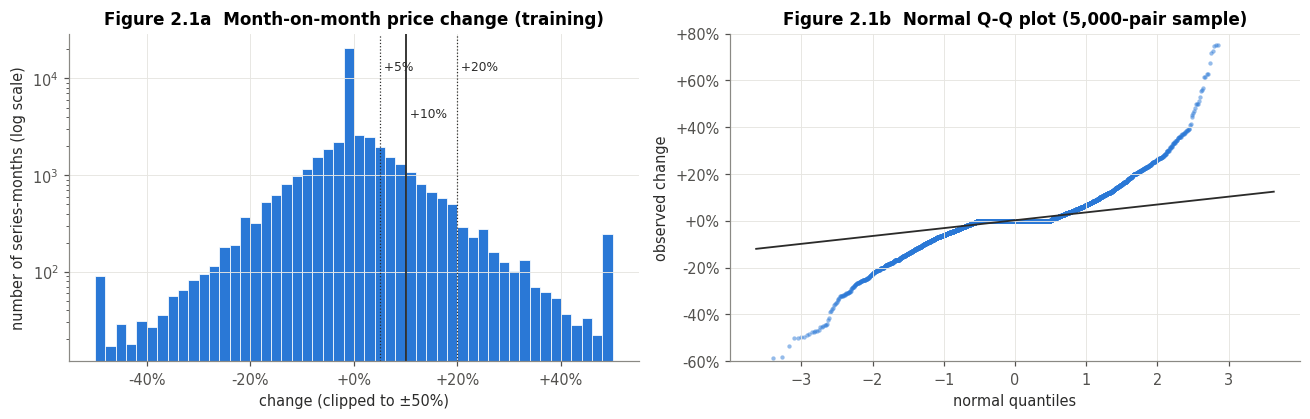

Share of changes above +10%: observed 11.8%  vs  a normal curve with the same IQR: 0.11%
Excess kurtosis (normal = 0): 543


In [18]:
# Figure 2.1 — distribution of monthly change, and its tails against a normal distribution
from scipy import stats
chg = train.loc[~entry_error, "change"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].hist(chg.clip(-0.5, 0.5), bins=np.arange(-0.5, 0.5001, 0.02), color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[0].set_yscale("log")
for t, ls in [(0.05, ":"), (0.10, "-"), (0.20, ":")]:
    axes[0].axvline(t, color="#2b2b2a", lw=1.2 if t == 0.10 else 0.8, ls=ls)
    axes[0].text(t, {0.05: 1.2e4, 0.10: 4e3, 0.20: 1.2e4}[t], f" +{t:.0%}", fontsize=8, color="#2b2b2a")
axes[0].set(title="Figure 2.1a  Month-on-month price change (training)",
            xlabel="change (clipped to ±50%)", ylabel="number of series-months (log scale)")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))

sample = chg.sample(5000, random_state=RANDOM_STATE)       # a sample keeps the Q-Q plot readable
(osm, osr), _ = stats.probplot(sample, dist="norm")
axes[1].scatter(osm, osr, s=8, color="#2a78d6", alpha=0.5, linewidths=0)
q1, q3 = np.percentile(sample, [25, 75]); zq1, zq3 = stats.norm.ppf([0.25, 0.75])
slope = (q3 - q1) / (zq3 - zq1); icpt = q1 - slope * zq1                # line through the quartiles
xx = np.array([osm.min(), osm.max()]); axes[1].plot(xx, icpt + slope * xx, color="#2b2b2a", lw=1.2)
axes[1].set_ylim(-0.6, 0.8)
axes[1].set(title="Figure 2.1b  Normal Q-Q plot (5,000-pair sample)", xlabel="normal quantiles", ylabel="observed change")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
plt.tight_layout(); plt.show()

sigma_robust = (chg.quantile(0.75) - chg.quantile(0.25)) / 1.349        # normal sigma implied by the IQR
p_normal = 1 - stats.norm.cdf(0.10, loc=chg.median(), scale=sigma_robust)
print(f"Share of changes above +10%: observed {(chg > 0.10).mean():.1%}  vs  a normal curve with the same IQR: {p_normal:.2%}")
print(f"Excess kurtosis (normal = 0): {stats.kurtosis(chg):.0f}")

**Figure 2.1 answers: how common are big rises, and is a +10% month unusual?**

- **(a)** Most months barely move: the bars pile up around 0%. But the right tail is long and thick, with thousands of rises above +10% and some above +40%.
- **(b)** In the Q-Q plot the points near the centre lie flat along 0% (the many unchanged prices), and both ends bend sharply away from the straight line: the tails are **far heavier than a normal distribution's**. A normal curve with the same IQR would expect **0.16%** of months to rise more than 10%; the data show **about 12%**, some **75 times** more.
- **Meaning for the project:** spikes are not rare noise around a bell curve; they are a regular feature of Tanzanian food prices, frequent enough (about one month in eight) to be learned from. It also rules out any method that assumes normally distributed changes, such as flagging spikes with a mean ± 2·SD rule.

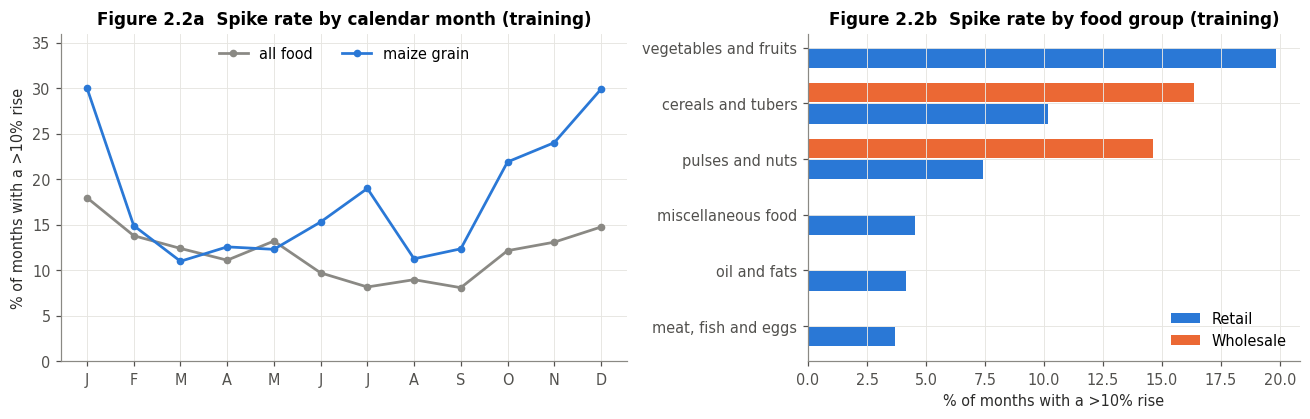

Spike rate by calendar month, maize grain (%): {1: 30.0, 2: 14.9, 3: 11.0, 4: 12.6, 5: 12.3, 6: 15.3, 7: 19.0, 8: 11.2, 9: 12.3, 10: 21.9, 11: 24.0, 12: 29.9}


In [19]:
# Figure 2.2 — when and where do spikes happen?
train["cal_month"] = train["month"].dt.month
is_maize_grain = train["commodity"].isin(["Maize", "Maize (white)"])
season = pd.DataFrame({"all food": train.groupby("cal_month")["spike"].mean(),
                       "maize grain": train[is_maize_grain].groupby("cal_month")["spike"].mean()}) * 100
by_cat = train.groupby(["category", "pricetype"])["spike"].mean().unstack() * 100
by_cat = by_cat.loc[by_cat.mean(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
months = list("JFMAMJJASOND")
axes[0].plot(season.index, season["all food"], color="#8a8984", lw=1.8, marker="o", ms=4, label="all food")
axes[0].plot(season.index, season["maize grain"], color="#2a78d6", lw=1.8, marker="o", ms=4, label="maize grain")
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(months)
axes[0].set(title="Figure 2.2a  Spike rate by calendar month (training)", ylabel="% of months with a >10% rise", ylim=(0, 36))
axes[0].legend(loc="upper center", ncol=2)

y = np.arange(len(by_cat)); h = 0.38
for k, pt in enumerate(["Retail", "Wholesale"]):
    vals = by_cat[pt]
    axes[1].barh(y + (k - 0.5) * h, vals, height=h * 0.92, color=COLOR[pt], label=pt)
axes[1].set_yticks(y); axes[1].set_yticklabels(by_cat.index)
axes[1].set(title="Figure 2.2b  Spike rate by food group (training)", xlabel="% of months with a >10% rise")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
print("Spike rate by calendar month, maize grain (%):", season["maize grain"].round(1).to_dict())

**Figure 2.2 answers: when and for which foods should the Ministry expect spikes?**

- **(a) Season.** For **maize grain**, the spike rate climbs from about **12–13%** in August–September to **21–30%** in **October–January**, then drops to about **11–15%** from February to May. This matches the **lean season before the main harvest**, when household stocks run down and market supply is tight. Across all foods the pattern is weaker but in the same direction (highest in December–January, lowest in August–September). Calendar month is therefore a useful feature, especially for cereals.
- **(b) Food group.** **Vegetables and fruits** spike most often (about **20%** of months; perishable, weather-dependent), then **cereals**. **Meat, oils and miscellaneous foods** rarely do (**about 4%**), partly because so many of their retail prices are carried forward unchanged (2.1.2). Wholesale prices exist only for cereals and pulses, and in both groups they **spike more often than retail** (about **16% vs 10%** for cereals, **14% vs 8%** for pulses).
- **Meaning:** a single national spike rate would hide large, predictable differences. The model needs commodity, price type and calendar month as inputs.

## 2.2 Justifying the 10% spike threshold [Condition 2]

The threshold is chosen from the **training years only**. Three pieces of evidence from the data, plus a sensitivity check:

In [20]:
q1, q3 = chg.quantile([0.25, 0.75]); iqr = q3 - q1
fence = q3 + 1.5 * iqr                                            # Tukey's upper fence (boxplot outlier rule, Lecture 3)
pctile_of_10 = (chg <= 0.10).mean()
print(f"Q1 = {q1:+.1%}, Q3 = {q3:+.1%}, IQR = {iqr:.1%}")
print(f"Tukey upper fence Q3 + 1.5·IQR = {fence:+.1%}")
print(f"+10% sits at the {pctile_of_10:.1%} percentile of monthly changes")

# Sensitivity: how the share of positives changes with the threshold, overall and by group
thresholds = [0.05, 0.10, 0.15, 0.20, 0.25]
sens = pd.DataFrame({f"> {t:.0%}": [(chg > t).mean()] +
                     [(train.loc[~entry_error & (train[c] == v), "change"] > t).mean()
                      for c, v in [("pricetype", "Retail"), ("pricetype", "Wholesale"),
                                   ("category", "cereals and tubers"), ("category", "vegetables and fruits"),
                                   ("category", "meat, fish and eggs")]]
                     for t in thresholds},
                    index=["all food", "retail", "wholesale", "cereals", "vegetables & fruits", "meat, fish & eggs"])
(sens * 100).round(1)

Q1 = -1.7%, Q3 = +2.7%, IQR = 4.4%
Tukey upper fence Q3 + 1.5·IQR = +9.3%
+10% sits at the 88.2% percentile of monthly changes


,> 5%,> 10%,> 15%,> 20%,> 25%
all food,19.6,11.8,6.8,4.0,2.5
retail,17.3,10.6,6.3,3.6,2.2
wholesale,27.7,15.9,8.8,5.4,3.4
cereals,22.2,12.9,7.1,4.1,2.5
vegetables & fruits,30.1,19.8,12.6,7.7,4.9
"meat, fish & eggs",7.1,3.7,1.6,0.4,0.3


**Decision: keep 10%.**

1. **It is almost exactly the boxplot outlier fence.** Tukey's rule (Lecture 3) calls a value unusually large when it exceeds Q3 + 1.5·IQR; for monthly price changes that fence is **+9.7%**. A “>10% rise” is therefore, by the course's own definition, an *unusually large* monthly increase rather than an arbitrary round number.
2. **It sits at the 88th percentile**, giving about **12%** positive cases: rare enough to be a warning signal, common enough (about 6,000 training spikes) for a classifier to learn from. At 20–25% the positives fall to 2.5–4% and are concentrated in vegetables; at 5% one month in five would be a “spike”, too many for the Ministry to act on.
3. **It is easy to communicate.** “Prices will rise by more than a tenth next month” needs no statistics to understand, which matters for a ministry audience (Section 5).

**Limitation, stated openly.** A single threshold treats volatile foods and stable foods alike: at 10%, vegetables spike in about 20% of months and meat in about 4%. A commodity-specific threshold was considered, but it would make “a spike” mean different things for different foods. Instead, commodity enters the model as a feature, so it can learn each food's normal volatility. Section 4 repeats the evaluation at **5%, 15% and 20%** to check that the conclusions do not depend on this choice.

## 2.3 Relationships

### 2.3.1 Correlation between staple prices, and its confounder

**Choice of measure.** Wholesale maize and rice prices are both **numeric (ratio)**, so a correlation is the right tool. Because both are right-skewed (2.1.1), **Spearman's rank correlation** is the main measure (it does not assume a straight-line, normally distributed relationship); Pearson is shown alongside. The three staples monitored throughout 2006–2021 are used, summarised as the **national median** wholesale price each month.

In [21]:
staples = ["Maize", "Rice", "Beans"]
nat = (train[(train["pricetype"] == "Wholesale") & train["commodity"].isin(staples)]
       .groupby(["month", "commodity"])["price_tzs_per_kg"].median().unstack()[staples].dropna())
print(f"Months with all three national medians: {len(nat)} ({nat.index.min()} – {nat.index.max()})")

t_idx = np.arange(len(nat))
annual_growth = {c: np.exp(np.polyfit(t_idx, np.log(nat[c]), 1)[0] * 12) - 1 for c in staples}
detrended = nat.apply(lambda y: y - np.polyval(np.polyfit(t_idx, y, 1), t_idx))   # remove each series' linear time trend
monthly = nat.pct_change().dropna()                                                # month-on-month changes

def pair(m, a="Maize", b="Rice"):
    return m[a].corr(m[b], method="spearman"), m[a].corr(m[b])

rows = {"price levels": pair(nat), "levels with time trend removed": pair(detrended), "month-on-month changes": pair(monthly)}
corr_table = pd.DataFrame(rows, index=["Spearman ρ", "Pearson r"]).T.round(2)
print("Average yearly price growth 2006–2021:", {c: f"{v:.1%}" for c, v in annual_growth.items()})
display(corr_table)
print("Spearman matrices — levels (left) vs month-on-month changes (right):")
display(pd.concat([nat.corr("spearman"), monthly.corr("spearman")], axis=1, keys=["levels", "changes"]).round(2))

Months with all three national medians: 182 (2006-02 – 2021-12)
Average yearly price growth 2006–2021: {'Maize': '7.0%', 'Rice': '6.4%', 'Beans': '8.2%'}


,Spearman ρ,Pearson r
price levels,0.79,0.75
levels with time trend removed,0.62,0.54
month-on-month changes,0.35,0.27


Spearman matrices — levels (left) vs month-on-month changes (right):


levels             changes            
commodity  Maize  Rice Beans   Maize  Rice Beans
commodity                                       
Maize       1.00  0.79  0.77    1.00  0.35  0.28
Rice        0.79  1.00  0.78    0.35  1.00  0.21
Beans       0.77  0.78  1.00    0.28  0.21  1.00

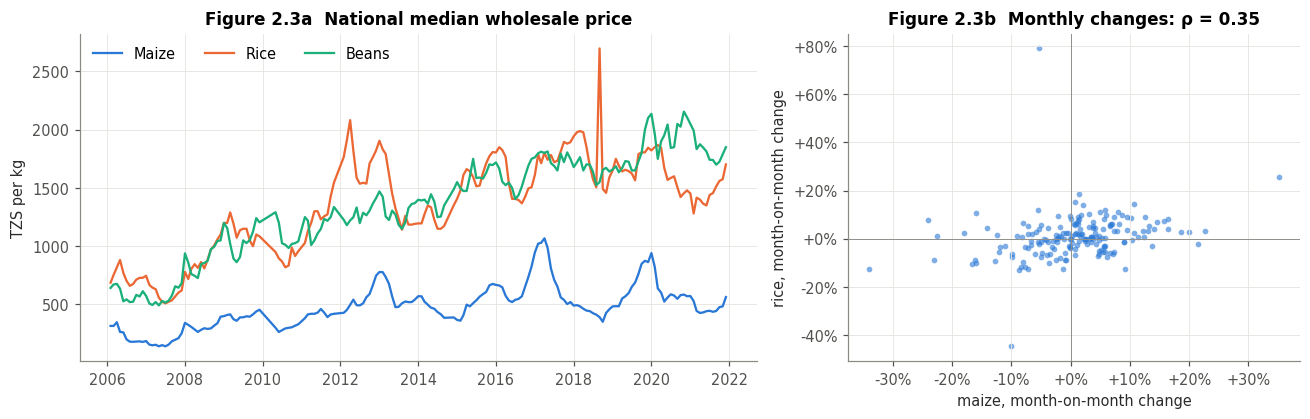

In [22]:
# Figure 2.3 — the shared trend behind the correlation
STAPLE_COLOR = {"Maize": "#2a78d6", "Rice": "#eb6834", "Beans": "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
for c in staples:
    axes[0].plot(nat.index.to_timestamp(), nat[c], color=STAPLE_COLOR[c], lw=1.5, label=c)
axes[0].set(title="Figure 2.3a  National median wholesale price", ylabel="TZS per kg")
axes[0].legend(loc="upper left", ncol=3)

axes[1].scatter(monthly["Maize"], monthly["Rice"], s=14, color="#2a78d6", alpha=0.6, linewidths=0)
axes[1].axhline(0, color="#8a8984", lw=0.6); axes[1].axvline(0, color="#8a8984", lw=0.6)
axes[1].set(title=f"Figure 2.3b  Monthly changes: ρ = {corr_table.loc['month-on-month changes', 'Spearman ρ']:.2f}",
            xlabel="maize, month-on-month change", ylabel="rice, month-on-month change")
for ax_ in (axes[1].xaxis, axes[1].yaxis):
    ax_.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
plt.tight_layout(); plt.show()

**Interpretation.** Wholesale maize and rice prices correlate at **ρ = 0.79** (Pearson r = 0.75), but **time — the general rise in prices — drives both**: over 2006–2021 maize rose about **6.8%** a year, rice **6.3%** and beans **8.1%** (Figure 2.3a). Remove each series' time trend and the correlation falls to **ρ = 0.62**; compare month-on-month changes, which is what a spike is about, and it falls to **ρ = 0.36** (Figure 2.3b).

The named confounder is the **general price level over time** (inflation together with rising transport and input costs), which pushes every food price up at once. It is plausible because it affects all three staples equally, and the evidence supports it: the strong correlations in the “levels” matrix (0.77–0.79) shrink to 0.19–0.36 in the “changes” matrix. Spearman matters here: the single rice outlier of September 2018 (+78% in Figure 2.3b, visible as the spike in 2.3a) would distort Pearson's r but barely moves a rank correlation.

**Meaning for the model.** Raw price *levels* mostly encode the year, not the risk of a spike. Features should therefore be **changes and ratios** (last month's change, price relative to the series' own recent average), not raw prices, otherwise the model would learn the calendar instead of market conditions. The remaining ρ ≈ 0.2–0.36 between staples' monthly changes is genuine co-movement, so a spike in one staple carries some warning for another.

### 2.3.2 Which attributes are associated with a spike? (χ² tests)

`spike` is binary and the candidate explanatory attributes here are nominal (commodity group, price type), binary (last month's spike) or treated as categories (calendar month), so the **χ² test of independence** is the right test (Lecture 4, Tutorial 2 §D). With about 49,000 pairs, even tiny differences give p ≈ 0, so the **effect size, Cramér's V** (0 = no association, 1 = perfect), is reported to judge how *strong* each association is.

In [23]:
def chi2_with_v(a, b):
    table = pd.crosstab(a, b)
    chi2, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return pd.Series({"χ²": chi2, "dof": dof, "p-value": p, "Cramér's V": v})

t2 = train.loc[~entry_error].copy()
t2["prev_spike"] = t2.groupby(SERIES_KEY)["spike"].shift()
# previous spike only counts when the previous month was itself a labelled consecutive pair
prev_month = t2.groupby(SERIES_KEY)["month"].shift()
months_apart = (t2["month"] - prev_month).apply(lambda x: x.n if pd.notna(x) else np.nan)
t2.loc[months_apart != 1, "prev_spike"] = np.nan

assoc = pd.DataFrame({
    "food group × spike": chi2_with_v(t2["category"], t2["spike"]),
    "commodity × spike": chi2_with_v(t2["commodity"], t2["spike"]),
    "calendar month × spike": chi2_with_v(t2["cal_month"], t2["spike"]),
    "price type × spike": chi2_with_v(t2["pricetype"], t2["spike"]),
    "spike last month × spike this month": chi2_with_v(t2["prev_spike"].dropna(), t2.loc[t2["prev_spike"].notna(), "spike"]),
}).T
display(assoc.round({"χ²": 0, "dof": 0, "Cramér's V": 3}).assign(**{"p-value": assoc["p-value"].map("{:.1e}".format)}))

persist = pd.crosstab(t2["prev_spike"], t2["spike"], normalize="index").rename(index={0: "no spike last month", 1: "spike last month"},
                                                                               columns={0: "no spike", 1: "spike"})
print("Chance of a spike this month, given last month:"); (persist * 100).round(1)

,χ²,dof,p-value,Cramér's V
food group × spike,1280.0,5.0,1.6e-274,0.165
commodity × spike,1924.0,28.0,0.0e+00,0.202
calendar month × spike,336.0,11.0,2.5e-65,0.084
price type × spike,222.0,1.0,4.1e-50,0.068
spike last month × spike this month,432.0,1.0,5.2e-96,0.098


Chance of a spike this month, given last month:


spike,no spike,spike
prev_spike,,
no spike last month,89.5,10.5
spike last month,79.8,20.2


**Interpretation.** All five associations are statistically significant (p < 0.001), as expected with this many pairs; Cramér's V shows which matter:

- **Commodity (V ≈ 0.20)** and **food group (V ≈ 0.17)** are the strongest: what is being sold matters most, consistent with Figure 2.2b.
- **Spike last month (V ≈ 0.1):** after a spike, the chance of another spike the next month roughly **doubles, from about 11% to 20%**. Spikes cluster, which gives a natural **baseline** for Section 4 (“predict a spike if there was one last month”) and a key feature.
- **Calendar month (V ≈ 0.09)** and **price type (V ≈ 0.06)** are weaker but real, in line with Figure 2.2a and the sticky retail prices.

**Not causal.** These are associations: for example, the lean season raises spike risk *through* supply, and part of the price-type effect comes from carried-forward retail prices, not from wholesale markets being inherently riskier.

## 2.4 Distance and similarity

### 2.4.1 Gower dissimilarity between series-months — worked example on real records

**Why Gower.** A series-month is described by **mixed attribute types**: nominal (commodity, food group, region), symmetric binary (price type), interval (latitude, longitude) and ratio (price, last month's change). Euclidean and Manhattan distance (Tutorial 2 §C) need numbers, so they cannot use commodity or region at all, and on raw prices the TZS scale would swamp everything else. The mixed-type dissimilarity of Han et al. (Ch. 2, often called **Gower's distance**) handles each attribute in its own way and averages them:

$$d(i,j)=\frac{1}{p}\sum_{f=1}^{p} d_{ij}^{(f)},\qquad d_{ij}^{(f)}=\begin{cases}0 \text{ if equal, } 1 \text{ if not} & \text{nominal / binary}\\[2pt] \min\!\left(1,\ \dfrac{|x_{if}-x_{jf}|}{\text{range}_f}\right) & \text{numeric}\end{cases}$$

Two choices are justified by the data: price enters as **log₁₀(TZS/kg)**, because prices are right-skewed and a 100 TZS difference means much more for maize than for beef; and the numeric ranges are taken from the **1st–99th percentiles of the training data**, so a single extreme value such as the 3,000,000 TZS/kg entry error cannot stretch the range and make every other price difference look like zero.

The three records are real, all from **December 2021**: **A** wholesale maize in Arusha, **B** wholesale maize in Babati (about 150 km away), **C** retail tomatoes in Arusha Region (same region as A).

In [24]:
NOMINAL = ["commodity", "category", "pricetype", "admin1"]
NUMERIC = ["latitude", "longitude", "log10_price", "change"]

train["log10_price"] = np.log10(train["price_tzs_per_kg"])
robust_range = {f: train[f].quantile(0.99) - train[f].quantile(0.01) for f in NUMERIC}   # training data only

def gower_parts(a, b):
    parts = {f: float(a[f] != b[f]) for f in NOMINAL}
    parts.update({f: min(1.0, abs(a[f] - b[f]) / robust_range[f]) for f in NUMERIC})
    return pd.Series(parts)

dec21 = train[train["month"] == pd.Period("2021-12", "M")]
pick = lambda c, pt, mk: dec21[(dec21["commodity"] == c) & (dec21["pricetype"] == pt) & (dec21["market"] == mk)].iloc[0]
A, B, C = pick("Maize", "Wholesale", "Arusha (urban)"), pick("Maize", "Wholesale", "Babati"), pick("Tomatoes", "Retail", "Arusha Region")

records = pd.DataFrame({"A": A, "B": B, "C": C}).loc[["market", "commodity", "category", "pricetype", "admin1",
                                                     "latitude", "longitude", "price_tzs_per_kg", "log10_price", "change"]]
display(records)
print("Robust ranges (P1–P99, training):", {f: round(v, 3) for f, v in robust_range.items()})

worked = pd.DataFrame({"d(A,B)": gower_parts(A, B), "d(A,C)": gower_parts(A, C), "d(B,C)": gower_parts(B, C)})
worked.loc["Gower distance = mean"] = worked.mean()
worked.round(3)

,A,B,C
market,Arusha (urban),Babati,Arusha Region
commodity,Maize,Maize,Tomatoes
category,cereals and tubers,cereals and tubers,vegetables and fruits
pricetype,Wholesale,Wholesale,Retail
admin1,Arusha,Manyara,Arusha
latitude,-3.37,-4.22,-2.97
longitude,36.68,35.75,35.92
price_tzs_per_kg,601.67,562.5,1187.6
log10_price,2.779358,2.750123,3.07467
change,0.226846,0.030541,0.142472


Robust ranges (P1–P99, training): {'latitude': np.float64(9.45), 'longitude': np.float64(10.09), 'log10_price': np.float64(1.585), 'change': np.float64(0.657)}


,"d(A,B)","d(A,C)","d(B,C)"
commodity,0.000,1.000,1.000
category,0.000,1.000,1.000
pricetype,0.000,1.000,1.000
admin1,1.000,0.000,1.000
latitude,0.090,0.042,0.132
longitude,0.092,0.075,0.017
log10_price,0.018,0.186,0.205
change,0.299,0.128,0.170
Gower distance = mean,0.187,0.429,0.566


In [25]:
# Check one numeric term by hand, then compare with plain Euclidean distance on raw numbers
f = "log10_price"
print(f"By hand, A vs C on {f}: |{A[f]:.3f} − {C[f]:.3f}| / {robust_range[f]:.3f} = {abs(A[f] - C[f]) / robust_range[f]:.3f}")

raw = ["price_tzs_per_kg", "latitude", "longitude"]
euc = lambda a, b: np.sqrt(((a[raw].astype(float) - b[raw].astype(float)) ** 2).sum())
print(f"Euclidean on raw (TZS/kg, lat, lon): A–B = {euc(A, B):.1f}, A–C = {euc(A, C):.1f}  "
      f"<- {abs(A['price_tzs_per_kg'] - C['price_tzs_per_kg']) ** 2 / euc(A, C) ** 2:.1%} of A–C comes from price alone")

By hand, A vs C on log10_price: |2.779 − 3.075| / 1.585 = 0.186
Euclidean on raw (TZS/kg, lat, lon): A–B = 39.2, A–C = 585.9  <- 100.0% of A–C comes from price alone


**Interpretation.**

- **A and B are the closest pair (Gower ≈ 0.19):** same commodity, food group and price type. Apart from the region, their largest difference is last month's change: Arusha maize rose **22.7%** in December 2021 (a spike) while Babati rose only **3.1%** (0.30 of the robust range). Two wholesale maize markets 150 km apart are near-neighbours, yet they can still behave differently in a given month.
- **A and C are much further apart (Gower ≈ 0.43) even though they are in the same region:** tomatoes (retail) and maize (wholesale) differ on commodity, food group and price type, and tomatoes cost about twice as much per kg. **Product matters more than place**, matching the χ² results in 2.3.2. B and C differ on almost everything (≈ 0.57).
- **Why not Euclidean?** On raw numbers, essentially **all** of the A–C distance (585.9 of 585.9) comes from the price difference in shillings; latitude and longitude barely register, and the four nominal attributes cannot be used at all. Gower gives each attribute a fair, comparable say.
- **Where this is used:** the same per-attribute treatment (one-hot for nominal attributes, robust scaling and log price for numeric ones) is what Section 3 applies before modelling.

### 2.4.2 Do nearby markets move together? Geographic distance vs price co-movement

The question is *where* the Ministry should look for warning signs. If nearby markets' prices move together, a spike in a neighbouring market is an early signal. For every pair of the 20 markets with long wholesale maize series, we compute two measures:

- **Geographic distance** with the **haversine formula** (great-circle distance on the Earth's surface from latitude and longitude; Euclidean distance on degrees would be distorted because a degree of longitude is not a fixed number of km).
- **Similarity of price behaviour**: the Pearson correlation of their month-on-month changes (correlation distance = 1 − r), over months both markets report (at least 36).

190 market pairs, 20 markets; Spearman ρ(distance, co-movement) = -0.49, p = 1.2e-12


,market_pairs,median_r
distance band,,
< 250 km,19,0.39
250–500,65,0.33
500–750,54,0.25
"750–1,000",37,0.21
"> 1,000 km",15,0.14


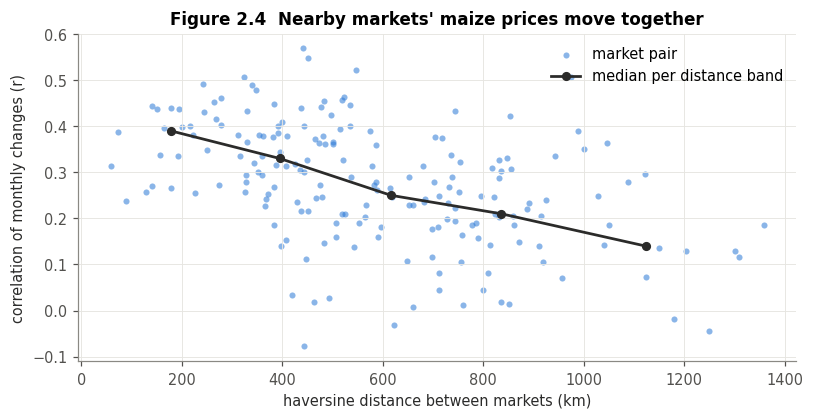

In [26]:
def haversine_km(lat1, lon1, lat2, lon2, R=6371.0):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

mz = train[(train["commodity"] == "Maize") & (train["pricetype"] == "Wholesale")]
wide = mz.pivot_table(index="month", columns="market", values="change")
loc = mz.drop_duplicates("market").set_index("market")[["latitude", "longitude"]]

pairs = []
names = list(wide.columns)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        both = wide[[names[i], names[j]]].dropna()
        if len(both) >= 36:
            a, b = loc.loc[names[i]], loc.loc[names[j]]
            pairs.append({"market_a": names[i], "market_b": names[j], "months": len(both),
                          "km": haversine_km(a.latitude, a.longitude, b.latitude, b.longitude),
                          "r": both.iloc[:, 0].corr(both.iloc[:, 1])})
pairs = pd.DataFrame(pairs)
rho_dist, p_dist = stats.spearmanr(pairs["km"], pairs["r"])
pairs["distance band"] = pd.cut(pairs["km"], [0, 250, 500, 750, 1000, 2000],
                                labels=["< 250 km", "250–500", "500–750", "750–1,000", "> 1,000 km"])
bands = pairs.groupby("distance band", observed=True)["r"].agg(market_pairs="size", median_r="median").round(2)
print(f"{len(pairs)} market pairs, {pairs[['market_a', 'market_b']].stack().nunique()} markets; "
      f"Spearman ρ(distance, co-movement) = {rho_dist:.2f}, p = {p_dist:.1e}")
display(bands)

fig, ax = plt.subplots(figsize=(7.5, 3.9))
ax.scatter(pairs["km"], pairs["r"], s=16, color="#2a78d6", alpha=0.55, linewidths=0, label="market pair")
mids = pairs.groupby("distance band", observed=True)["km"].median()
ax.plot(mids.values, bands["median_r"].values, color="#2b2b2a", lw=1.8, marker="o", ms=5, label="median per distance band")
ax.set(title="Figure 2.4  Nearby markets' maize prices move together", xlabel="haversine distance between markets (km)",
       ylabel="correlation of monthly changes (r)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

**Interpretation.** The closer two markets are, the more their maize prices move together: the median correlation of monthly changes is about **0.35 for markets under 250 km apart** and about **0.19 beyond 1,000 km**, and distance and co-movement are clearly negatively related (Spearman ρ ≈ **−0.47**, p < 0.001). Markets are linked by trade, so supply shocks spread to neighbours first.

Even neighbours correlate only moderately (r rarely above 0.5), so every market keeps its own local dynamics. **Meaning for the model:** a useful feature is the **average price change last month in markets within about 250 km** (computed from past months only [Condition 1]). For the Ministry, this means a spike in one market is a reason to watch its neighbours next month.

## 2.5 What the exploration means for the next steps

| Finding (training data) | Evidence | Consequence |
|---|---|---|
| Prices and changes are right-skewed with very heavy tails; one entry error distorts the mean | 2.1, Figure 2.1 | Robust statistics; outliers handled within each series; robust scaling and log price (§3) |
| 10% ≈ boxplot outlier fence, 88th percentile, ~12% positives | 2.2 | Threshold fixed at 10%; sensitivity at 5/15/20% (§4) [Condition 2] |
| Retail prices often unchanged (46% exact zeros) | 2.1.2 | Price type is a feature; staleness noted as a limit (§5) |
| Spike risk depends on commodity, season and price type | Figure 2.2, 2.3.2 | Commodity, food group, price type and calendar month as features |
| Spikes cluster: risk doubles after a spike | 2.3.2 | Last month's change/spike as features; “repeat last month” as a baseline (§4) |
| Price levels share a time trend (confounder) | 2.3.1, Figure 2.3 | Use changes and ratios, not raw price levels |
| Nearby markets co-move; distant ones much less | 2.4.2, Figure 2.4 | Neighbouring-market change from past months as a feature |
| Mixed attribute types | 2.4.1 | Per-type treatment: one-hot nominal, robust-scaled numeric (§3) |

---
# References

**Data**
- World Food Programme (2026). *United Republic of Tanzania — Food Prices* and *Markets*. Humanitarian Data Exchange. https://data.humdata.org/dataset/wfp-food-prices-for-united-republic-of-tanzania. CC BY-IGO. Downloaded 9 November 2026.

**Course and textbook**
- Nyalala, I. (2026). *Z3003 Data Mining: Scaling to Large Data*, Lectures 1–5 and Tutorials 1–2. IIT Madras Zanzibar.

**Methods**
- Gower, J. C. (1971). A general coefficient of similarity and some of its properties. *Biometrics*, 27(4), 857–871. (Mixed-type distance, §2.4.1.)
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley. (Boxplot fence Q3 + 1.5·IQR, §2.2.)

**Software** (versions are printed in the setup cell)
- The pandas development team. *pandas*. https://pandas.pydata.org — McKinney, W. (2010). Data structures for statistical computing in Python. *Proc. 9th Python in Science Conference*, 56–61.
- Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95.
- Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272. (Used for `chi2_contingency`, `probplot`, `spearmanr`.)